# Aktienanalyse der Microsoft Corporation (MSFT)

## Detailliertes Reporting für eine Aktie

**Unternehmen:** Microsoft Corporation  
**Ticker:** MSFT  
**Datenquelle:** Yahoo Finance über die Python-Bibliothek `yfinance`  
**Analysezeitraum:** 01.01.2021 bis 31.12.2025  
**Arbeitsumgebung:** Python / Jupyter Notebook

## 1. Einleitung und Zielsetzung

Ziel des Projekts ist die Analyse der historischen Wertentwicklung, Rendite und des Risikos der Microsoft-Aktie von 2021 bis 2025. Die Daten werden mit Python ausgewertet und durch Tabellen sowie geeignete Visualisierungen ergänzt. Abschließend erfolgt ein Vergleich mit dem S&P 500 als Benchmark auf einer möglichst einheitlichen Total-Return-Basis.

### 1.1 Auswahl des Unternehmens

Microsoft Corporation (MSFT) wird als einzelnes börsennotiertes Unternehmen untersucht. Für die fünf ausgewählten Kalenderjahre stehen durchgehend tägliche Kursdaten zur Verfügung. Damit können Kursentwicklung, Rendite, Volatilität und zwischenzeitliche Verluste anhand derselben Aktie nachvollziehbar analysiert werden.

### 1.2 Auswahl des Analysezeitraums

Der Analysezeitraum umfasst die fünf Kalenderjahre 2021 bis 2025. Der erste verfügbare Handelstag ist der 04.01.2021, der letzte der 31.12.2025. Damit stehen ausreichend tägliche Beobachtungen für die Rendite- und Risikoanalyse zur Verfügung.

### 1.3 Datenquelle, Methode und Werkzeuge

Die historischen Tagesdaten werden mit `yfinance` von [Yahoo Finance: MSFT](https://finance.yahoo.com/quote/MSFT/history/) und [Yahoo Finance: S&P 500 Total Return (`^SP500TR`)](https://finance.yahoo.com/quote/%5ESP500TR/) abgerufen. Das jeweilige Abrufdatum wird beim Ausführen angezeigt. Zur Verarbeitung, Berechnung und Darstellung dienen pandas, NumPy und Matplotlib. Alle Tabellen und Abbildungen sind eigene Berechnungen bzw. Darstellungen auf Basis dieser Daten.

Bei Microsoft bewirkt `auto_adjust=True`, dass die OHLC-Kurswerte um Dividenden und Aktiensplits bereinigt werden. Der S&P 500 wird über den Total-Return-Index `^SP500TR` berücksichtigt, der Dividenden einbezieht. So beziehen sich die verglichenen Reihen möglichst auf dieselbe Ertragsbasis. Die auf bereinigten MSFT-Kursen beruhende Wertentwicklung ist eine Näherung für Total Return, da sie nicht centgenau mit einer realen Wiederanlage aller Ausschüttungen übereinstimmen muss. Die Kennzahlen beruhen auf historischen USD-Daten, ohne Steuern oder Transaktionskosten.

Der Parameter `end="2026-01-01"` ist exklusiv und schließt dadurch den letzten Handelstag 2025 ein. Für die Annualisierung werden 252 Handelstage pro Jahr angenommen; die Sharpe Ratio verwendet einen risikofreien Zinssatz von 0 %.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf

In [2]:
print("Bibliotheken wurden erfolgreich geladen.")

Bibliotheken wurden erfolgreich geladen.


## 2. Datenbeschaffung und Datenprüfung

Für die Analyse werden historische Tagesdaten der Microsoft-Aktie mit `yfinance` von Yahoo Finance abgerufen. Der betrachtete Zeitraum reicht vom 01.01.2021 bis zum 31.12.2025 und umfasst damit fünf vollständige Kalenderjahre. Da an Börsenfeiertagen und Wochenenden kein Handel stattfindet, beginnt die Datenreihe am 04.01.2021.

In [3]:
microsoft = yf.Ticker("MSFT")
data = microsoft.history(start="2021-01-01", end="2026-01-01", auto_adjust=True)

if data.empty:
    raise ValueError("Keine Microsoft-Kursdaten geladen.")

print("Abrufdatum der Microsoft-Daten:", pd.Timestamp.now().strftime("%d.%m.%Y"))
data.head()

Abrufdatum der Microsoft-Daten: 25.09.2026


,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
2021-01-04 00:00:00-05:00,212.180275,212.628417,204.819326,207.565384,37130100,0.0,0.0
2021-01-05 00:00:00-05:00,207.155361,208.356769,205.667918,207.765594,23823000,0.0,0.0
2021-01-06 00:00:00-05:00,202.302106,206.421193,202.082808,202.378387,35930700,0.0,0.0
2021-01-07 00:00:00-05:00,204.085131,209.138635,203.770492,208.137466,27694500,0.0,0.0
2021-01-08 00:00:00-05:00,208.509326,210.320967,206.936072,209.405609,22956200,0.0,0.0


In [4]:
data = data[["Open", "High", "Low", "Close", "Volume"]]
data.head()

,Open,High,Low,Close,Volume
Date,,,,,
2021-01-04 00:00:00-05:00,212.180275,212.628417,204.819326,207.565384,37130100
2021-01-05 00:00:00-05:00,207.155361,208.356769,205.667918,207.765594,23823000
2021-01-06 00:00:00-05:00,202.302106,206.421193,202.082808,202.378387,35930700
2021-01-07 00:00:00-05:00,204.085131,209.138635,203.770492,208.137466,27694500
2021-01-08 00:00:00-05:00,208.509326,210.320967,206.936072,209.405609,22956200


In [5]:
type(data)

pandas.core.frame.DataFrame

### 2.1 Aufbau der Daten

Der Datensatz enthält für jeden Handelstag verschiedene Informationen:

- **Open:** bereinigter Kurs zu Beginn des Handelstages
- **High:** höchster bereinigter Kurs des Tages
- **Low:** niedrigster bereinigter Kurs des Tages
- **Close:** bereinigter Schlusskurs des Tages
- **Volume:** Anzahl der gehandelten Aktien

Für die folgenden Analysen wird hauptsächlich der bereinigte Schlusskurs verwendet. Das Handelsvolumen ist keine Kursgröße.

### 2.2 Umfang des Datensatzes

Die folgende Ausgabe zeigt die Zahl der Handelstage und der ausgewählten Variablen. Der Umfang wird anschließend anhand der tatsächlich geladenen Daten beurteilt.

In [6]:
print("Anzahl der Handelstage:", len(data))
print("Anzahl der Spalten:", len(data.columns))

Anzahl der Handelstage: 1255
Anzahl der Spalten: 5


### 2.3 Prüfung auf fehlende Werte

In [7]:
data.isnull().sum()

Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64

In den fünf ausgewählten Variablen liegen laut der vorstehenden Prüfung keine fehlenden Werte vor. Daher ist an dieser Stelle keine zusätzliche Bereinigung erforderlich.

In [8]:
data.info() # Mit data.info() wird die Struktur des Datensatzes überprüft

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1255 entries, 2021-01-04 00:00:00-05:00 to 2025-12-31 00:00:00-05:00
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Open    1255 non-null   float64
 1   High    1255 non-null   float64
 2   Low     1255 non-null   float64
 3   Close   1255 non-null   float64
 4   Volume  1255 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 58.8 KB


Die Kursvariablen liegen als numerische Werte (float64) und das Handelsvolumen als Ganzzahl (int64) vor. Damit können die Daten direkt für die weiteren statistischen Berechnungen verwendet werden.

### 2.4 Deskriptive Statistik

Die deskriptive Statistik liefert einen ersten Überblick über die Verteilung der Kurs- und Volumendaten. Dazu gehören Anzahl der Beobachtungen, Mittelwert, Standardabweichung, Minimum, Quartile und Maximum.

In [9]:
# describe() erstellt eine statistische Zusammenfassung der numerischen Daten.
# round(2) rundet die Ausgabe auf zwei Dezimalstellen.
data.describe().round(2)

,Open,High,Low,Close,Volume
count,1255.00,1255.00,1255.00,1255.00,1255.00
mean,340.50,343.61,337.24,340.56,25535292.99
std,88.94,89.19,88.44,88.82,10097830.33
min,202.30,204.53,202.08,202.38,5855900.00
25%,262.48,266.32,259.24,263.12,18906950.00
50%,322.40,324.98,319.16,321.87,23176100.00
75%,412.11,415.28,408.66,411.52,29489100.00
max,549.80,550.01,536.36,537.65,90428900.00


Die vorstehende Ausgabe zeigt den durchschnittlichen, niedrigsten und höchsten bereinigten Schlusskurs im Untersuchungszeitraum. Diese Werte beschreiben die historische Kursreihe; sie sind keine Renditekennzahlen.

## 3. Analyse der Kursentwicklung

Der tägliche bereinigte Schlusskurs wird über den Untersuchungszeitraum visualisiert, um die langfristige Wertentwicklung und stärkere Schwankungsphasen sichtbar zu machen.

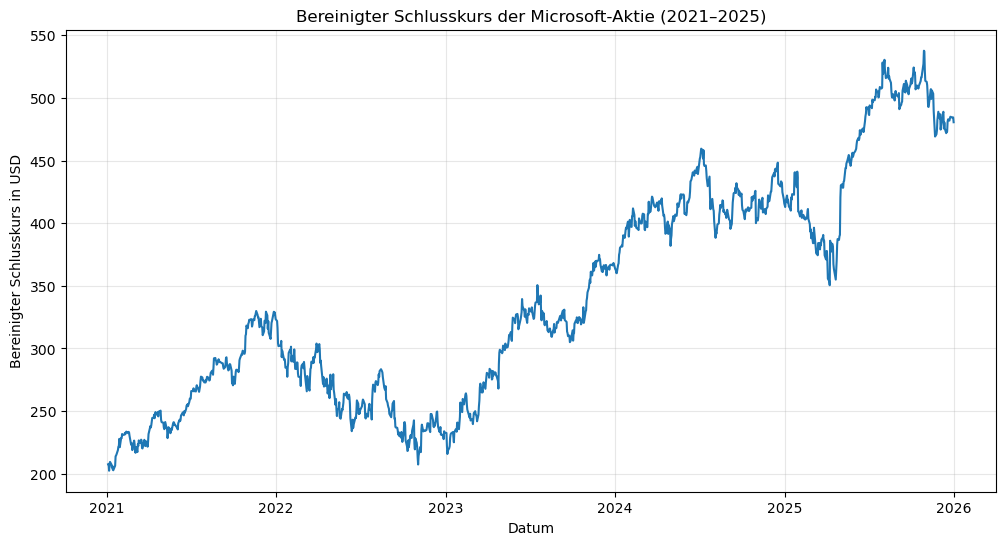

In [10]:
plt.figure(figsize=(12, 6))
plt.plot(data.index, data["Close"], linewidth=1.5)
plt.title("Bereinigter Schlusskurs der Microsoft-Aktie (2021–2025)")
plt.xlabel("Datum")
plt.ylabel("Bereinigter Schlusskurs in USD")
plt.grid(alpha=0.3)
plt.show()

### 3.1 Wichtige Kurswerte

Zusätzlich zur Grafik werden der erste, letzte, niedrigste und höchste bereinigte Schlusskurs des Untersuchungszeitraums ermittelt.

In [11]:
start_price = data["Close"].iloc[0] # iloc greift über die Position auf Werte zu.
end_price = data["Close"].iloc[-1]
lowest_price = data["Close"].min()
highest_price = data["Close"].max()

print("Bereinigter Schlusskurs zu Beginn:", round(start_price, 2), "USD")
print("Bereinigter Schlusskurs am Ende:", round(end_price, 2), "USD")
print("Niedrigster bereinigter Schlusskurs:", round(lowest_price, 2), "USD")
print("Höchster bereinigter Schlusskurs:", round(highest_price, 2), "USD")

Bereinigter Schlusskurs zu Beginn: 207.57 USD
Bereinigter Schlusskurs am Ende: 480.57 USD
Niedrigster bereinigter Schlusskurs: 202.38 USD
Höchster bereinigter Schlusskurs: 537.65 USD


Die Ausgabe zeigt den ersten und letzten sowie den niedrigsten und höchsten bereinigten Microsoft-Schlusskurs im Untersuchungszeitraum. Der letzte Wert liegt deutlich über dem ersten.

### 3.2 Wertveränderung im gesamten Zeitraum

Auf Basis des ersten und letzten bereinigten Schlusskurses wird die prozentuale Wertveränderung über den gesamten Untersuchungszeitraum berechnet. Dadurch lässt sich die Entwicklung in einer einzelnen Kennzahl zusammenfassen.

In [12]:
price_change = ((end_price - start_price) / start_price) * 100
print("Wertveränderung im gesamten Zeitraum:", round(price_change, 2), "%")

Wertveränderung im gesamten Zeitraum: 131.53 %


Der bereinigte Schlusskurs und damit die daraus abgeleitete Wertentwicklung steigen über den Untersuchungszeitraum deutlich. Die genaue prozentuale Veränderung ist in der vorstehenden Ausgabe angegeben.

## 4. Renditeanalyse

Neben der Wertentwicklung ist die Rendite eine wichtige Kennzahl zur Beurteilung einer Aktie. Im folgenden Abschnitt werden die täglichen Renditen der Microsoft-Aktie berechnet und untersucht.

### 4.1 Tägliche Rendite

Die tägliche Rendite beschreibt die prozentuale Veränderung des bereinigten Schlusskurses gegenüber dem vorherigen Handelstag.

In [13]:
data["Return"] = data["Close"].pct_change() # pct_change() berechnet die relative Änderung gegenüber dem vorherigen Wert.
data[["Close", "Return"]].head()

,Close,Return
Date,,
2021-01-04 00:00:00-05:00,207.565384,NaN
2021-01-05 00:00:00-05:00,207.765594,0.000965
2021-01-06 00:00:00-05:00,202.378387,-0.025929
2021-01-07 00:00:00-05:00,208.137466,0.028457
2021-01-08 00:00:00-05:00,209.405609,0.006093


Für den ersten Handelstag kann keine Rendite berechnet werden, da im Datensatz kein vorheriger Schlusskurs vorhanden ist. Daher enthält die erste Zeile den Wert NaN.

### 4.2 Statistische Analyse der täglichen Renditen
Zur Untersuchung der täglichen Renditen werden grundlegende statistische Kennzahlen berechnet.
Die Ergebnisse werden auf vier Dezimalstellen gerundet, da tägliche Renditen häufig relativ kleine Werte aufweisen.

In [14]:
data["Return"].describe().round(4)

count    1254.0000
mean        0.0008
std         0.0162
min        -0.0772
25%        -0.0076
50%         0.0008
75%         0.0100
max         0.1013
Name: Return, dtype: float64

Zur besseren Interpretation der täglichen Renditen werden zusätzlich die durchschnittliche, die höchste und die niedrigste Tagesrendite berechnet. Die Werte werden in Prozent umgerechnet.

In [15]:
average_daily_return = data["Return"].mean() * 100
best_day = data["Return"].max() * 100
worst_day = data["Return"].min() * 100

print("Durchschnittliche tägliche Rendite:", round(average_daily_return, 3), "%")
print("Beste Tagesrendite:", round(best_day, 2), "%")
print("Schlechteste Tagesrendite:", round(worst_day, 2), "%")

Durchschnittliche tägliche Rendite: 0.08 %
Beste Tagesrendite: 10.13 %
Schlechteste Tagesrendite: -7.72 %


Die täglichen Veränderungen sind im Durchschnitt relativ klein.
Einzelne Handelstage können jedoch deutlich stärkere positive oder negative Ausschläge aufweisen.

### 4.3 Annualisierte durchschnittliche Rendite

Die durchschnittliche tägliche Rendite wird arithmetisch auf 252 Handelstage hochgerechnet. Die Kennzahl ist damit die **annualisierte durchschnittliche Rendite**, nicht die tatsächlich in jedem Kalenderjahr erzielte Rendite und nicht die geometrische Jahresrendite (CAGR).

In [16]:
trading_days = 252
annual_return = data["Return"].mean() * trading_days

print("Annualisierte durchschnittliche Rendite:", round(annual_return * 100, 2), "%")

Annualisierte durchschnittliche Rendite: 20.17 %


Die annualisierte durchschnittliche Rendite der Microsoft-Aktie ergibt sich aus der mittleren Tagesrendite mal 252. Sie ermöglicht einen Vergleich mit entsprechend berechneten Kennzahlen anderer Anlagen, bildet aber keine garantierte Jahresrendite ab.

### 4.4 Kumulative Rendite

Die kumulative Rendite zeigt die gesamte Wertentwicklung auf Basis der bereinigten Schlusskurse seit Beginn des Untersuchungszeitraums und berücksichtigt die Verkettung der täglichen Renditen.

In [17]:
# fillna(0) ersetzt fehlende Werte (NaN) durch 0
# cumprod() multipliziert die Werte schrittweise und berechnet das fortlaufende Produkt
data["Cumulative_Return"] = (1 + data["Return"].fillna(0)).cumprod() - 1
data[["Return", "Cumulative_Return"]].head()

,Return,Cumulative_Return
Date,,
2021-01-04 00:00:00-05:00,NaN,0.000000
2021-01-05 00:00:00-05:00,0.000965,0.000965
2021-01-06 00:00:00-05:00,-0.025929,-0.024990
2021-01-07 00:00:00-05:00,0.028457,0.002756
2021-01-08 00:00:00-05:00,0.006093,0.008866


### 4.5 Entwicklung der kumulativen Rendite

Die kumulative Rendite wird über den gesamten Zeitraum visualisiert. Die Grafik zeigt, wann besonders starke Zuwächse und Rückgänge auftraten.

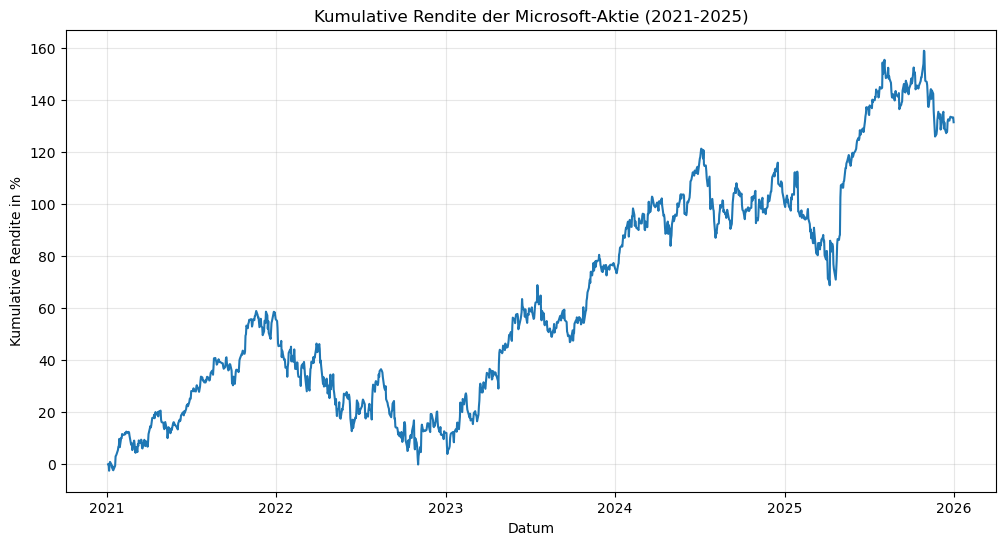

In [18]:
plt.figure(figsize=(12, 6))
plt.plot(data.index, data["Cumulative_Return"] * 100, linewidth=1.5)
plt.title("Kumulative Rendite der Microsoft-Aktie (2021-2025)")
plt.xlabel("Datum")
plt.ylabel("Kumulative Rendite in %")
plt.grid(alpha=0.3)
plt.show()

In [19]:
final_cumulative_return = data["Cumulative_Return"].iloc[-1] * 100

print("Kumulative Rendite am Ende des Zeitraums:", round(final_cumulative_return, 2), "%")    

Kumulative Rendite am Ende des Zeitraums: 131.53 %


Die kumulative Rendite am Ende des Untersuchungszeitraums entspricht der aus erstem und letztem bereinigtem Schlusskurs berechneten Wertveränderung. Eine hypothetische Anlage hätte ihren Wert auf dieser Berechnungsbasis mehr als verdoppelt; Steuern und Transaktionskosten sind dabei nicht berücksichtigt.

## 5. Risikoanalyse

Das Risiko der Microsoft-Aktie wird anhand von Volatilität, rollierender Volatilität und Maximum Drawdown untersucht.

### 5.1 Volatilität
Die Volatilität beschreibt, wie stark die Renditen einer Aktie schwanken. Eine höhere Volatilität bedeutet stärkere Schwankungen der Renditen und weist grundsätzlich auf ein höheres Schwankungsrisiko hin.  
Zur Berechnung der täglichen Volatilität wird die Standardabweichung der täglichen Renditen verwendet. Anschließend wird die tägliche Volatilität auf Jahresbasis hochgerechnet.

In [20]:
daily_volatility = data["Return"].std()
annual_volatility = daily_volatility * np.sqrt(252) # np.sqrt() berechnet die Quadratwurzel eines Wertes

print("Tägliche Volatilität:", round(daily_volatility * 100, 2),"%")
print("Annualisierte Volatilität:", round(annual_volatility * 100, 2),"%")    

Tägliche Volatilität: 1.62 %
Annualisierte Volatilität: 25.71 %


Die Kennzahlen der Volatilität zeigen, dass die Renditen der Aktie im Untersuchungszeitraum deutlichen Schwankungen unterlagen.

### 5.2 Maximum Drawdown
Der Maximum Drawdown zeigt den größten prozentualen Verlust von einem zuvor erreichten Höchststand bis zu einem späteren Tiefpunkt.
Diese Kennzahl ist hilfreich, um zu beurteilen, welchen maximalen zwischenzeitlichen Verlust eine Investition innerhalb des untersuchten Zeitraums erfahren hätte.

In [21]:
wealth_index = (1 + data["Return"].fillna(0)).cumprod()
running_max = wealth_index.cummax() # cummax() gibt für jede Position den bisher höchsten erreichten Wert zurück

data["Drawdown"] = wealth_index / running_max - 1
max_drawdown = data["Drawdown"].min()

print("Maximum Drawdown:", round(max_drawdown * 100, 2), "%")    

max_drawdown_date = data["Drawdown"].idxmin() # idxmin() gibt den Index des kleinsten Wertes zurück

print("Datum des Maximum Drawdown:", max_drawdown_date.date())    

Maximum Drawdown: -37.15 %
Datum des Maximum Drawdown: 2022-11-03


Der Maximum Drawdown der Microsoft-Aktie beträgt rund −37,15 %. Der stärkste Rückgang gegenüber einem zuvor erreichten Höchststand wurde am 03.11.2022 erreicht.

### 5.3 Entwicklung des Drawdowns
Die Drawdown-Grafik zeigt mehrere deutliche Rückgangsphasen. Damit wird sichtbar, dass eine langfristig positive Wertentwicklung dennoch mit erheblichen zwischenzeitlichen Verlusten verbunden sein kann.

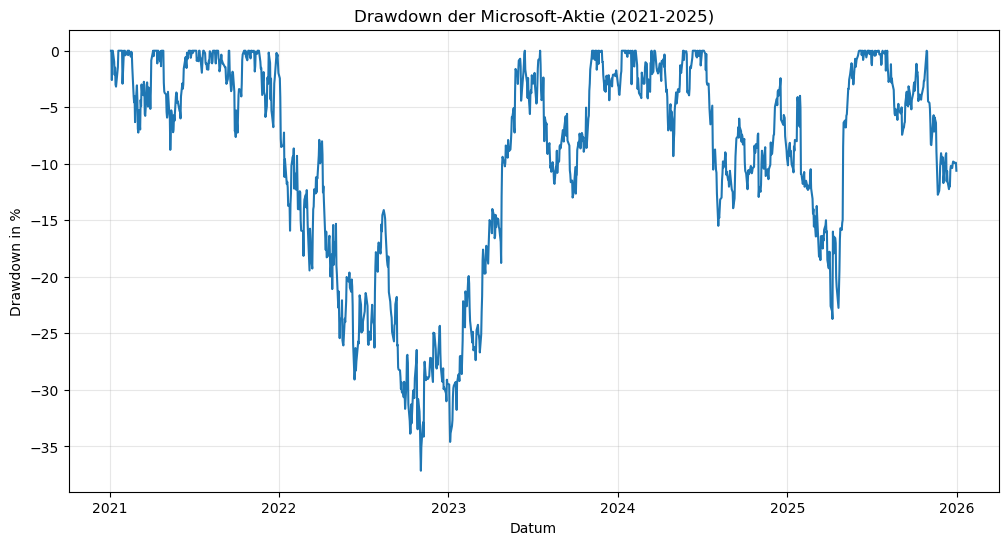

In [22]:
plt.figure(figsize=(12, 6))

plt.plot(data.index, data["Drawdown"] * 100, linewidth=1.5)
plt.title("Drawdown der Microsoft-Aktie (2021-2025)")
plt.xlabel("Datum")
plt.ylabel("Drawdown in %")
plt.grid(alpha=0.3)
plt.show()

Die Drawdown-Grafik zeigt, dass die Microsoft-Aktie trotz ihrer langfristig positiven Entwicklung mehrere deutliche Rückgangsphasen aufweist. Dies verdeutlicht, dass eine positive langfristige Rendite nicht bedeutet, dass eine Investition während des gesamten Zeitraums ohne größere zwischenzeitliche Verluste verläuft.

### 5.4 Entwicklung der Volatilität

Da das Schwankungsrisiko einer Aktie im Zeitverlauf nicht konstant ist, wird zusätzlich die rollierende Volatilität über jeweils 30 **Handelstage** berechnet. Das Fenster von 30 Handelstagen dient als kurzfristiger Betrachtungszeitraum, um Veränderungen der Volatilität im Zeitverlauf sichtbar zu machen.

Die 30-Tage-Standardabweichung wird mit der Wurzel aus 252 annualisiert, um die Werte mit der Gesamtvolatilität vergleichen zu können. Zu Beginn des Zeitraums fehlen die für ein vollständiges Fenster erforderlichen Beobachtungen.

In [23]:
# rolling(30) bildet ein gleitendes Fenster aus 30 aufeinanderfolgenden Handelstagen.
data["Rolling_Volatility"] = data["Return"].rolling(30).std() * np.sqrt(trading_days) * 100

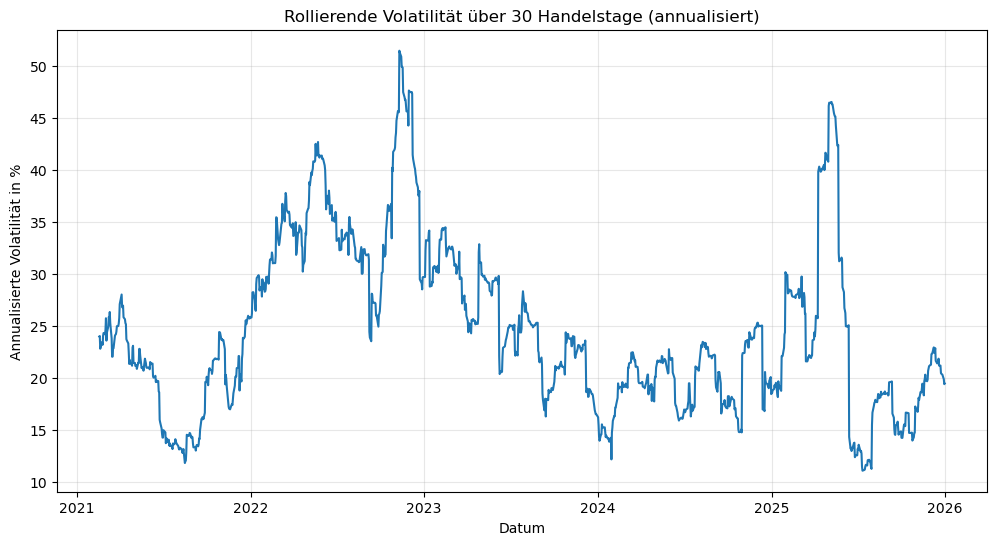

In [24]:
plt.figure(figsize=(12, 6))
plt.plot(data.index, data["Rolling_Volatility"], linewidth=1.5)
plt.title("Rollierende Volatilität über 30 Handelstage (annualisiert)")
plt.xlabel("Datum")
plt.ylabel("Annualisierte Volatilität in %")
plt.grid(alpha=0.3)
plt.show()

Die Grafik zeigt, dass die Volatilität im Untersuchungszeitraum nicht konstant ist. In einzelnen Phasen treten deutlich stärkere Schwankungen auf als in anderen. Damit ergänzt die rollierende Volatilität die bisherige Risikoanalyse um eine zeitliche Perspektive.

In [25]:
average_volatility = data["Rolling_Volatility"].mean()
maximum_volatility = data["Rolling_Volatility"].max()
maximum_volatility_date = data["Rolling_Volatility"].idxmax() # idxmax() gibt den Index des größten Wertes zurück.

print("Durchschnittliche annualisierte 30-Handelstage-Volatilität:", round(average_volatility, 2), "%")
print("Maximale annualisierte 30-Handelstage-Volatilität:", round(maximum_volatility, 2), "%")
print("Datum der maximalen Volatilität:", maximum_volatility_date.date())

Durchschnittliche annualisierte 30-Handelstage-Volatilität: 24.6 %
Maximale annualisierte 30-Handelstage-Volatilität: 51.49 %
Datum der maximalen Volatilität: 2022-11-10


### 5.5 Interpretation der Volatilität

Die durchschnittliche annualisierte Volatilität der rollierenden 30-Handelstage-Fenster liegt im Untersuchungszeitraum bei rund **24,60 %**. Das Maximum von rund **51,49 %** tritt am **10. November 2022** auf. Die Werte zeigen, dass das Schwankungsrisiko im Zeitverlauf variiert. Der Durchschnitt der rollierenden Werte ist nicht identisch mit der aus allen Tagesrenditen berechneten annualisierten Gesamtvolatilität.

## 6. Bewertung der Aktie – Risiko und Rendite

Nachdem Rendite, Drawdown und Volatilität einzeln untersucht wurden, werden die wichtigsten Kennzahlen gemeinsam betrachtet. Dazu dienen:

- annualisierte durchschnittliche Rendite
- annualisierte Volatilität
- Maximum Drawdown
- Sharpe Ratio

### 6.1 Annualisierte durchschnittliche Rendite

In [26]:
annualized_return = data["Return"].mean() * trading_days

print("Annualisierte durchschnittliche Rendite:", round(annualized_return * 100, 2), "%")

Annualisierte durchschnittliche Rendite: 20.17 %


Die annualisierte durchschnittliche Rendite ergibt sich aus dem arithmetischen Mittel der Tagesrenditen mal 252. Sie sollte nicht isoliert betrachtet werden, da eine höhere Rendite mit einem höheren Risiko verbunden sein kann.

### 6.2 Sharpe Ratio

In [27]:
annualized_volatility = data["Return"].std() * np.sqrt(trading_days)
risk_free_rate = 0.0
sharpe_ratio = (annualized_return - risk_free_rate) / annualized_volatility

print("Annualisierte durchschnittliche Rendite:", round(annualized_return * 100, 2), "%")
print("Annualisierte Volatilität:", round(annualized_volatility * 100, 2), "%")
print("Sharpe Ratio (risikofreier Zinssatz: 0 %):", round(sharpe_ratio, 2))

Annualisierte durchschnittliche Rendite: 20.17 %
Annualisierte Volatilität: 25.71 %
Sharpe Ratio (risikofreier Zinssatz: 0 %): 0.78


Die Sharpe Ratio setzt die über den angenommenen risikofreien Zinssatz hinausgehende annualisierte durchschnittliche Rendite ins Verhältnis zur annualisierten Volatilität. Hier wird vereinfachend ein **risikofreier Zinssatz von 0 %** verwendet. Ein höherer Wert bedeutet eine höhere Rendite je Einheit des so gemessenen Schwankungsrisikos; andere Risikoarten werden dadurch nicht erfasst.

### 6.3 Zusammenfassung der Risiko-Rendite-Kennzahlen

In [28]:
summary = {
    "Kennzahl": [
        "Annualisierte durchschnittliche Rendite",
        "Annualisierte Volatilität",
        "Durchschnittliche annualisierte 30-Handelstage-Volatilität",
        "Maximale annualisierte 30-Handelstage-Volatilität",
        "Maximum Drawdown",
        "Sharpe Ratio (risikofreier Zinssatz: 0 %)"
    ],
    "Wert": [
        f"{annualized_return * 100:.2f} %",
        f"{annualized_volatility * 100:.2f} %",
        f"{average_volatility:.2f} %",
        f"{maximum_volatility:.2f} %",
        f"{max_drawdown * 100:.2f} %",
        f"{sharpe_ratio:.2f}"
    ]
}
summary_df = pd.DataFrame(summary)
summary_df

,Kennzahl,Wert
0,Annualisierte durchschnittliche Rendite,20.17 %
1,Annualisierte Volatilität,25.71 %
2,Durchschnittliche annualisierte 30-Handelstage...,24.60 %
3,Maximale annualisierte 30-Handelstage-Volatilität,51.49 %
4,Maximum Drawdown,-37.15 %
5,Sharpe Ratio (risikofreier Zinssatz: 0 %),0.78


Die Tabelle fasst die Rendite- und Risikokennzahlen der Microsoft-Aktie zusammen. Die annualisierte durchschnittliche Rendite ist positiv, während Volatilität und Maximum Drawdown auf erhebliche Schwankungen und zwischenzeitliche Verluste hinweisen. Die Sharpe Ratio verwendet in dieser Analyse einen risikofreien Zinssatz von **0 %**.

### 6.4 Gesamtbewertung des Risiko-Rendite-Profils

Eine höhere Rendite allein belegt noch kein günstigeres Risiko-Rendite-Profil. Deshalb werden die Microsoft-Kennzahlen im nächsten Schritt denen des S&P 500 gegenübergestellt und anschließend gemeinsam in einem Risiko-Rendite-Diagramm gezeigt.

### 6.5 Benchmark-Analyse: Microsoft vs. S&P 500

Der S&P 500 dient als Benchmark für die Einordnung der Microsoft-Aktie. Für eine möglichst einheitliche Ertragsbasis wird der **S&P 500 Total Return Index** verwendet; sein Yahoo-Finance-Ticker ist `^SP500TR`. Dieser Index berücksichtigt Dividenden. Er ist daher für die bereinigte Microsoft-Kursreihe geeigneter als der reine S&P-500-Preisindex `^GSPC`.

Für beide Reihen gilt derselbe Untersuchungszeitraum von 2021 bis 2025. Die Daten werden anhand gemeinsamer Handelstage zusammengeführt.

#### 6.5.1 Laden der Benchmark-Daten

Die historischen Kursdaten des S&P 500 Total Return Index (`^SP500TR`) werden für denselben Untersuchungszeitraum wie die Microsoft-Daten geladen.

In [29]:
start_date = data.index.min()
end_date = data.index.max()

if start_date.tzinfo is not None:
    start_date = start_date.tz_localize(None) # tz_localize(None) entfernt die Zeitzoneninformation eines Datums.

if end_date.tzinfo is not None:
    end_date = end_date.tz_localize(None)

end_date = end_date + pd.Timedelta(days=1) # Timedelta beschreibt eine Zeitspanne.

sp500 = yf.download(
    "^SP500TR",
    start=start_date,
    end=end_date,
    auto_adjust=True,
    progress=False
)

if sp500.empty:
    raise ValueError("Keine S&P-500-Total-Return-Daten geladen.")

print("Abrufdatum der Benchmark-Daten:", pd.Timestamp.now().strftime("%d.%m.%Y"))
sp500.head()

Abrufdatum der Benchmark-Daten: 25.09.2026


Price,Close,High,Low,Open,Volume
Ticker,^SP500TR,^SP500TR,^SP500TR,^SP500TR,^SP500TR
Date,,,,,
2021-01-04,7645.270020,7788.350098,7567.080078,7777.410156,0
2021-01-05,7700.339844,7722.689941,7635.640137,7640.770020,0
2021-01-06,7744.430176,7744.430176,7744.430176,7744.430176,0
2021-01-07,7861.100098,7876.669922,7780.350098,7780.350098,0
2021-01-08,7905.279785,7909.319824,7820.379883,7885.359863,0


#### 6.5.2 Kontrolle der geladenen Daten

Vor der weiteren Analyse werden Spalten, Zeitraum und Umfang des Benchmark-Datensatzes geprüft.

In [30]:
print(sp500.columns)

print()

print("Erstes Datum:", sp500.index.min())
print("Letztes Datum:", sp500.index.max())

print()

print(sp500.shape)

MultiIndex([( 'Close', '^SP500TR'),
            (  'High', '^SP500TR'),
            (   'Low', '^SP500TR'),
            (  'Open', '^SP500TR'),
            ('Volume', '^SP500TR')],
           names=['Price', 'Ticker'])

Erstes Datum: 2021-01-04 00:00:00
Letztes Datum: 2025-12-31 00:00:00

(1255, 5)


#### 6.5.3 Vereinheitlichung der Datenstruktur

Abhängig von der verwendeten `yfinance`-Version können die geladenen Benchmark-Daten einen MultiIndex besitzen. Für die weitere Analyse wird in diesem Fall die erste Ebene der Spaltenbezeichnungen übernommen.

In [31]:
# isinstance() prüft, ob ein Objekt einem bestimmten Datentyp entspricht
if isinstance(sp500.columns, pd.MultiIndex):
    
    # get_level_values(0) gibt die Werte der ersten Ebene eines MultiIndex zurück
    sp500.columns = sp500.columns.get_level_values(0)
    
sp500.head()

Price,Close,High,Low,Open,Volume
Date,,,,,
2021-01-04,7645.270020,7788.350098,7567.080078,7777.410156,0
2021-01-05,7700.339844,7722.689941,7635.640137,7640.770020,0
2021-01-06,7744.430176,7744.430176,7744.430176,7744.430176,0
2021-01-07,7861.100098,7876.669922,7780.350098,7780.350098,0
2021-01-08,7905.279785,7909.319824,7820.379883,7885.359863,0


#### 6.5.4 Vereinheitlichung der Zeitindizes

Die Microsoft- und Benchmark-Daten können unterschiedliche Zeitzoneninformationen enthalten. Für den täglichen Vergleich werden beide Indizes in ein Datumsformat umgewandelt und mögliche Zeitzoneninformationen entfernt. Dadurch lassen sich die Zeitreihen anhand ihrer Handelstage zusammenführen.

In [32]:
data.index = pd.to_datetime(data.index) # to_datetime() wandelt Werte in ein Datums- und Zeitformat um
sp500.index = pd.to_datetime(sp500.index)

if data.index.tz is not None:
    data.index = data.index.tz_localize(None)

if sp500.index.tz is not None:
    sp500.index = sp500.index.tz_localize(None)

print("Microsoft timezone:", data.index.tz)
print("S&P 500 timezone:", sp500.index.tz)

Microsoft timezone: None
S&P 500 timezone: None


#### 6.5.5 Auswahl der Schlusskurse

Für den Vergleich werden die bereinigten Microsoft-Schlusskurse und die Indexstände des S&P 500 Total Return ausgewählt. Beide Reihen werden als eindimensionale Series bereitgestellt.

In [33]:
msft_close = data["Close"].copy() # copy() erstellt eine unabhängige Kopie eines Objekts

if isinstance(msft_close, pd.DataFrame):
    msft_close = msft_close.iloc[:, 0]

sp500_close = sp500["Close"].copy()

if isinstance(sp500_close, pd.DataFrame):
    sp500_close = sp500_close.iloc[:, 0]

print(type(msft_close))
print(type(sp500_close))

<class 'pandas.core.series.Series'>
<class 'pandas.core.series.Series'>


#### 6.5.6 Zusammenführung der Zeitreihen

Die beiden Reihen werden nach Handelstag zu einem gemeinsamen DataFrame zusammengeführt. Berücksichtigt werden nur Tage mit Werten in beiden Reihen; eventuell fehlende Werte werden entfernt. Damit beruhen beide Kennzahlensätze auf derselben Beobachtungsbasis.

In [47]:
# concat() verbindet Pandas-Objekte zu einem gemeinsamen Objekt.
comparison = pd.concat( 
    [msft_close.rename("Microsoft"),
     sp500_close.rename("S&P 500 (Total Return)")],
    axis=1,
    join="inner" # join="inner" übernimmt nur in beiden Reihen vorhandene Handelstage.
).dropna() # dropna() entfernt Zeilen mit fehlenden Werten.

comparison.head()

,Microsoft,S&P 500 (Total Return)
Date,,
2021-01-04,207.565384,7645.270020
2021-01-05,207.765594,7700.339844
2021-01-06,202.378387,7744.430176
2021-01-07,208.137466,7861.100098
2021-01-08,209.405609,7905.279785


In [35]:
comparison.tail()

,Microsoft,S&P 500 (Total Return)
Date,,
2025-12-24,484.943420,15409.700195
2025-12-26,484.635406,15406.480469
2025-12-29,484.029236,15353.160156
2025-12-30,484.406860,15332.070312
2025-12-31,480.571167,15220.450195


In [36]:
print("Anzahl gemeinsamer Handelstage:", len(comparison))
print("Beginn:", comparison.index.min().date())
print("Ende:", comparison.index.max().date())

Anzahl gemeinsamer Handelstage: 1255
Beginn: 2021-01-04
Ende: 2025-12-31


Nach der Zusammenführung umfasst der gemeinsame Datensatz **1.255 Handelstage** vom **04.01.2021** bis zum **31.12.2025**. Damit stehen für Microsoft und den S&P 500 über den gesamten Untersuchungszeitraum vergleichbare Beobachtungen zur Verfügung.

#### 6.5.7 Vergleich der Wertentwicklung

Die absoluten Kurs- und Indexniveaus sind nicht direkt vergleichbar. Beide Reihen werden deshalb auf einen gemeinsamen Startwert von **100** normiert. Ein Wert von 150 entspricht einer Wertsteigerung von 50 % seit dem gemeinsamen Startdatum.

In [37]:
# div() dividiert Werte elementweise durch andere Werte
# mul() multipliziert Werte elementweise mit einem angegebenen Wert
normalized = comparison.div(comparison.iloc[0]).mul(100)
normalized.head()

,Microsoft,S&P 500 (Total Return)
Date,,
2021-01-04,100.000000,100.000000
2021-01-05,100.096457,100.720312
2021-01-06,97.501030,101.297013
2021-01-07,100.275616,102.823054
2021-01-08,100.886576,103.400923


##### Grafischer Vergleich

Die normierten Wertentwicklungen von Microsoft und dem S&P 500 Total Return werden gemeinsam dargestellt. Die horizontale Linie bei 100 kennzeichnet den Ausgangswert.

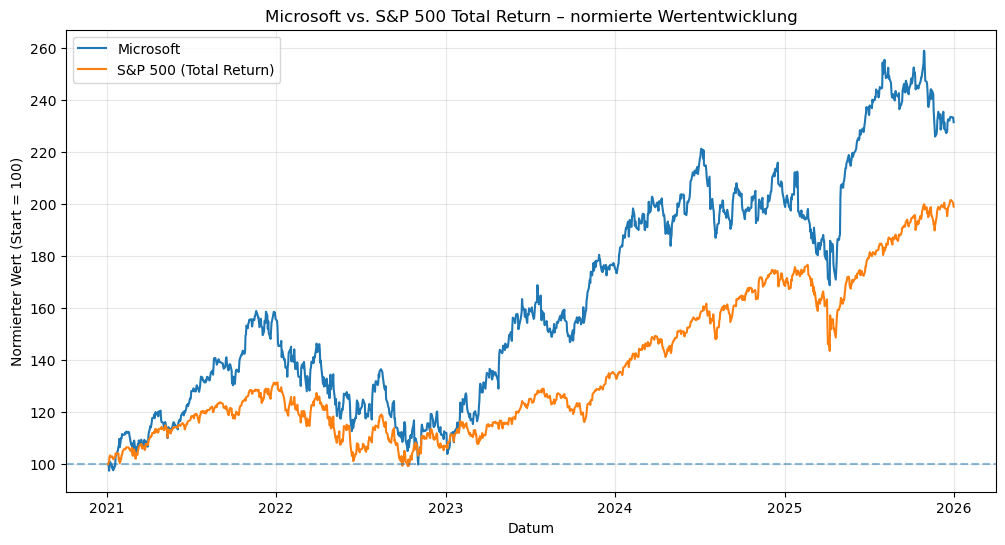

In [38]:
plt.figure(figsize=(12, 6))
plt.plot(normalized.index, normalized["Microsoft"], label="Microsoft")
plt.plot(normalized.index, normalized["S&P 500 (Total Return)"], label="S&P 500 (Total Return)")
plt.axhline(100, linestyle="--", alpha=0.5) # axhline() fügt eine horizontale Referenzlinie ein.
plt.title("Microsoft vs. S&P 500 Total Return – normierte Wertentwicklung")
plt.xlabel("Datum")
plt.ylabel("Normierter Wert (Start = 100)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

#### 6.5.8 Tägliche Renditen

Für die weitere Benchmark-Analyse werden aus den gemeinsamen Werten die täglichen Renditen beider Reihen berechnet. Die erste Beobachtung entfällt, weil für sie kein vorheriger Wert vorliegt.

In [39]:
comparison_returns = comparison.pct_change().dropna()
comparison_returns.head()

,Microsoft,S&P 500 (Total Return)
Date,,
2021-01-05,0.000965,0.007203
2021-01-06,-0.025929,0.005726
2021-01-07,0.028457,0.015065
2021-01-08,0.006093,0.005620
2021-01-11,-0.009699,-0.006556


In [40]:
comparison_returns.describe().round(4)

,Microsoft,S&P 500 (Total Return)
count,1254.0000,1254.0000
mean,0.0008,0.0006
std,0.0162,0.0107
min,-0.0772,-0.0596
25%,-0.0076,-0.0046
50%,0.0008,0.0009
75%,0.0100,0.0063
max,0.1013,0.0952


Die deskriptive Auswertung erlaubt den Vergleich von Durchschnitt, Streuung und Extremwerten der Tagesrenditen. Die beiden Reihen beruhen dabei auf denselben Handelstagen.

#### 6.5.9 Korrelation und Beta der täglichen Renditen

Die Korrelation misst die Stärke des linearen Zusammenhangs zwischen den täglichen Renditen. Die Matrix wird mit `comparison_returns.corr()` berechnet. Das **Beta** der Microsoft-Aktie gegenüber dem S&P 500 ist die Kovarianz der beiden täglichen Renditereihen, geteilt durch die Varianz der täglichen Marktrenditen. Ein Beta über 1 bedeutet, dass Microsoft im betrachteten Zeitraum im Mittel stärker auf Marktbewegungen reagierte; die Kennzahl beschreibt einen historischen statistischen Zusammenhang, keine sichere Vorhersage oder Kausalität.

In [41]:
correlation_matrix = comparison_returns.corr()
correlation_with_market = correlation_matrix.loc["Microsoft", "S&P 500 (Total Return)"]
correlation_matrix.round(4)

,Microsoft,S&P 500 (Total Return)
Microsoft,1.0000,0.7614
S&P 500 (Total Return),0.7614,1.0000


In [42]:
market_returns = comparison_returns["S&P 500 (Total Return)"]
msft_returns = comparison_returns["Microsoft"]
beta_msft = msft_returns.cov(market_returns) / market_returns.var()
beta_market = market_returns.cov(market_returns) / market_returns.var()

print("Korrelation Microsoft / S&P 500:", round(correlation_with_market, 4))
print("Beta Microsoft gegenüber dem S&P 500:", round(beta_msft, 4))

Korrelation Microsoft / S&P 500: 0.7614
Beta Microsoft gegenüber dem S&P 500: 1.1547


In [43]:
msft_annual_return = comparison_returns["Microsoft"].mean() * trading_days
sp500_annual_return = comparison_returns["S&P 500 (Total Return)"].mean() * trading_days

msft_annual_volatility = comparison_returns["Microsoft"].std() * np.sqrt(trading_days)
sp500_annual_volatility = comparison_returns["S&P 500 (Total Return)"].std() * np.sqrt(trading_days)

msft_sharpe = (msft_annual_return - risk_free_rate) / msft_annual_volatility
sp500_sharpe = (sp500_annual_return - risk_free_rate) / sp500_annual_volatility

msft_drawdown = comparison["Microsoft"] / comparison["Microsoft"].cummax() - 1
sp500_drawdown = comparison["S&P 500 (Total Return)"] / comparison["S&P 500 (Total Return)"].cummax() - 1

msft_max_drawdown = msft_drawdown.min()
sp500_max_drawdown = sp500_drawdown.min()

In [44]:
benchmark_summary = pd.DataFrame({
    "Kennzahl": [
        "Annualisierte durchschnittliche Rendite",
        "Annualisierte Volatilität",
        "Maximum Drawdown",
        "Sharpe Ratio (risikofreier Zinssatz: 0 %)",
        "Korrelation der Tagesrenditen mit dem Markt",
        "Beta gegenüber dem S&P 500"
    ],
    "Microsoft": [
        f"{msft_annual_return * 100:.2f} %",
        f"{msft_annual_volatility * 100:.2f} %",
        f"{msft_max_drawdown * 100:.2f} %",
        f"{msft_sharpe:.2f}",
        f"{correlation_with_market:.2f}",
        f"{beta_msft:.2f}"
    ],
    "S&P 500 (Total Return)": [
        f"{sp500_annual_return * 100:.2f} %",
        f"{sp500_annual_volatility * 100:.2f} %",
        f"{sp500_max_drawdown * 100:.2f} %",
        f"{sp500_sharpe:.2f}",
        f"{correlation_matrix.loc['S&P 500 (Total Return)', 'S&P 500 (Total Return)']:.2f}",
        f"{beta_market:.2f}"
    ]
})
benchmark_summary

,Kennzahl,Microsoft,S&P 500 (Total Return)
0,Annualisierte durchschnittliche Rendite,20.17 %,15.28 %
1,Annualisierte Volatilität,25.71 %,16.96 %
2,Maximum Drawdown,-37.15 %,-24.49 %
3,Sharpe Ratio (risikofreier Zinssatz: 0 %),0.78,0.90
4,Korrelation der Tagesrenditen mit dem Markt,0.76,1.00
5,Beta gegenüber dem S&P 500,1.15,1.00


##### Drawdown-Vergleich

Die Kurven zeigen für jeden Handelstag den prozentualen Abstand zum jeweils zuvor erreichten Höchststand. Je tiefer die Kurve unter null fällt, desto größer war der bis dahin aufgetretene zwischenzeitliche Verlust. Die Gesamtminima stehen zusätzlich in der Vergleichstabelle.

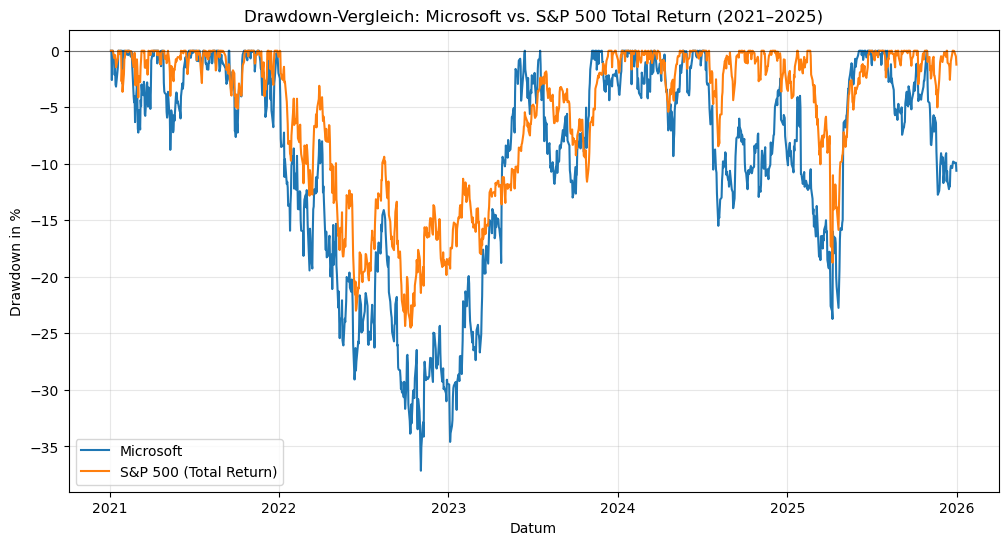

In [45]:
plt.figure(figsize=(12, 6))
plt.plot(msft_drawdown.index, msft_drawdown * 100, label="Microsoft", linewidth=1.5)
plt.plot(sp500_drawdown.index, sp500_drawdown * 100, label="S&P 500 (Total Return)", linewidth=1.5)
plt.axhline(0, color="black", linewidth=0.8, alpha=0.5)
plt.title("Drawdown-Vergleich: Microsoft vs. S&P 500 Total Return (2021–2025)")
plt.xlabel("Datum")
plt.ylabel("Drawdown in %")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

##### Risiko-Rendite-Vergleich

Die beiden Punkte stellen die annualisierte durchschnittliche Rendite der beiden Reihen gegen ihre annualisierte Volatilität. Damit lässt sich der Renditevorsprung von Microsoft zusammen mit dem höheren Schwankungsrisiko ablesen.

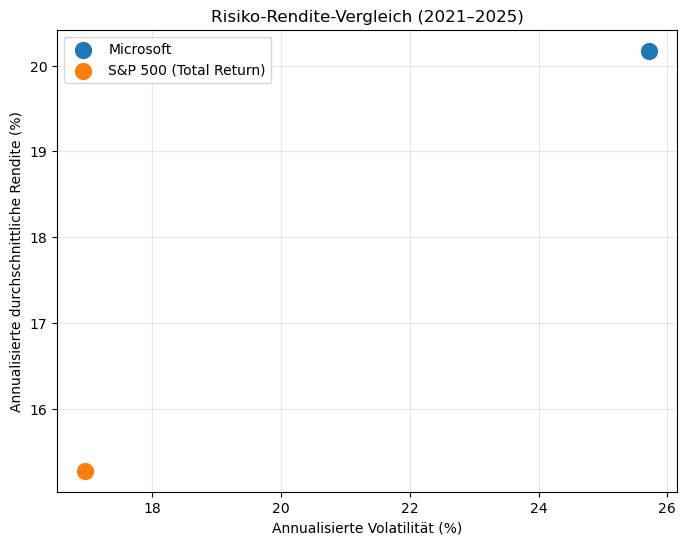

In [46]:
plt.figure(figsize=(8, 6))
plt.scatter(msft_annual_volatility * 100, msft_annual_return * 100, s=130, label="Microsoft")
plt.scatter(sp500_annual_volatility * 100, sp500_annual_return * 100, s=130, label="S&P 500 (Total Return)")
plt.xlabel("Annualisierte Volatilität (%)")
plt.ylabel("Annualisierte durchschnittliche Rendite (%)")
plt.title("Risiko-Rendite-Vergleich (2021–2025)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

#### 6.5.10 Ergebnisvergleich

Die Vergleichstabelle und die folgenden Diagramme zeigen die Kennzahlen auf derselben Datenbasis. Microsoft erreicht die höhere **annualisierte durchschnittliche Rendite**, weist jedoch zugleich die höhere **annualisierte Volatilität** und den größeren Verlust im **Maximum Drawdown** auf. Die Sharpe Ratio ist beim S&P 500 Total Return höher. Die Korrelation und das Beta beschreiben zusätzlich den Zusammenhang der täglichen Renditen mit dem Markt; sie ersetzen keine Risikokennzahl. Alle Sharpe-Ratios verwenden denselben risikofreien Zinssatz von **0 %**.

## 7. Fazit

In diesem Projekt wurde die historische Wertentwicklung der Microsoft-Aktie von 2021 bis 2025 mit Python untersucht. Analysiert wurden tägliche und kumulative Renditen sowie mehrere Risikokennzahlen. Als Benchmark diente der S&P 500 Total Return Index.

### Ergebnisse der Microsoft-Analyse

Der bereinigte Microsoft-Schlusskurs stieg über den Untersuchungszeitraum deutlich. Die annualisierte durchschnittliche Rendite lag bei rund **20,17 %**, die annualisierte Volatilität bei rund **25,71 %**. Der Maximum Drawdown von rund **−37,15 %** zeigt, dass die positive langfristige Entwicklung mit erheblichen zwischenzeitlichen Verlusten verbunden war.

### Vergleich mit dem S&P 500

Microsoft erzielte die höhere annualisierte durchschnittliche Rendite (**20,17 %** gegenüber rund **15,28 %**). Gleichzeitig waren die annualisierte Volatilität (**25,71 %** gegenüber rund **16,96 %**) und der Maximum Drawdown (**−37,15 %** gegenüber rund **−24,49 %**) größer als beim S&P 500 Total Return. Der direkte Drawdown-Vergleich macht die unterschiedlich starken Rückgänge im Zeitverlauf sichtbar. Bei einem risikofreien Zinssatz von **0 %** lag die Sharpe Ratio von Microsoft bei rund **0,78**, die des Benchmarks bei rund **0,90**. Die täglichen Renditen korrelierten positiv (**r ≈ 0,76**); Microsoft wies gegenüber dem Benchmark ein Beta von rund **1,15** auf. Microsoft erzielte somit den höheren Ertrag, aber auf Basis dieser Kennzahlen kein besseres risikoadjustiertes Ergebnis.

### Kritische Reflexion

Die Ergebnisse beruhen auf historischen Yahoo-Finance-Daten. Nachträgliche Datenkorrekturen können einzelne Werte beim erneuten Abruf leicht verändern. Die bereinigte Microsoft-Kursreihe ist eine Näherung für eine Anlage mit berücksichtigten Ausschüttungen; eine konkrete Wiederanlagestrategie wurde nicht simuliert. Steuern, Transaktionskosten und Wechselkursrisiken werden nicht berücksichtigt.

Die annualisierte durchschnittliche Rendite ist das arithmetische Mittel der Tagesrenditen, hochgerechnet mit **252 Handelstagen**. Sie ist nicht mit einer geometrischen Jahresrendite gleichzusetzen. Die Sharpe Ratio wurde vereinfachend mit einem risikofreien Zinssatz von **0 %** berechnet. Volatilität beschreibt nur die Streuung der Renditen und erfasst nicht alle Anlagerisiken. Auch Korrelation und Beta sind historische, vom Zeitraum abhängige Kennzahlen; sie belegen keine Kausalität. Maximum Drawdown und Sharpe Ratio hängen ebenfalls vom gewählten Zeitraum und den genannten Annahmen ab. Die Vergangenheit erlaubt keine sichere Prognose für die künftige Entwicklung.